In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set visualization style
sns.set_theme(style="whitegrid")

# Generate reproducible dataset
np.random.seed(42)

n = 300

data = {
    "total_bill": np.random.uniform(10, 100, n),
    "size": np.random.randint(1, 7, n),
    "day": np.random.choice(
        ["Thursday", "Friday", "Saturday", "Sunday"], n
    ),
    "time": np.random.choice(["Lunch", "Dinner"], n),
    "smoker": np.random.choice(["Yes", "No"], n)
}

df = pd.DataFrame(data)

# Generate tip amounts
df["tip"] = (
    df["total_bill"] *
    np.random.uniform(0.10, 0.25, n)
).round(2)

# Create additional metrics
df["tip_percentage"] = (
    df["tip"] / df["total_bill"] * 100
)

df["bill_per_person"] = (
    df["total_bill"] / df["size"]
)

# Display dataset
print("Dataset Shape:", df.shape)
display(df.head(10))

Dataset Shape: (300, 8)


,total_bill,size,day,time,smoker,tip,tip_percentage,bill_per_person
0,43.708611,5,Friday,Dinner,No,5.27,12.057121,8.741722
1,95.564288,4,Sunday,Lunch,No,22.46,23.502503,23.891072
2,75.879455,6,Sunday,Dinner,No,17.53,23.102433,12.646576
3,63.879264,3,Thursday,Dinner,No,12.11,18.957639,21.293088
4,24.041678,4,Thursday,Lunch,No,4.57,19.008657,6.010419
5,24.039507,5,Sunday,Lunch,Yes,4.80,19.967132,4.807901
6,15.227525,2,Sunday,Lunch,No,1.92,12.608746,7.613763
7,87.955853,4,Saturday,Dinner,Yes,20.86,23.716443,21.988963
8,64.100351,2,Friday,Lunch,No,10.44,16.286962,32.050176
9,73.726532,6,Saturday,Dinner,Yes,11.61,15.747384,12.287755


In [2]:
# Check dataset information

print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check categorical values
print("\nUnique Days:", df["day"].unique())
print("Meal Types:", df["time"].unique())
print("Smoker Categories:", df["smoker"].unique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   total_bill       300 non-null    float64
 1   size             300 non-null    int64  
 2   day              300 non-null    object 
 3   time             300 non-null    object 
 4   smoker           300 non-null    object 
 5   tip              300 non-null    float64
 6   tip_percentage   300 non-null    float64
 7   bill_per_person  300 non-null    float64
dtypes: float64(4), int64(1), object(3)
memory usage: 18.9+ KB

Missing Values:
total_bill         0
size               0
day                0
time               0
smoker             0
tip                0
tip_percentage     0
bill_per_person    0
dtype: int64

Duplicate Records:
0

Statistical Summary:


,total_bill,size,tip,tip_percentage,bill_per_person
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,54.568414,3.486667,9.726833,17.938857,21.960065
std,26.490649,1.671067,5.391630,4.454917,20.061784
min,10.455543,1.000000,1.250000,10.091842,2.124170
25%,31.517272,2.000000,5.205000,13.948393,9.186016
50%,56.054596,4.000000,8.955000,18.496684,15.320154
75%,78.117365,5.000000,14.095000,21.814659,26.880824
max,99.104847,6.000000,23.600000,24.973984,97.291887



Unique Days: ['Friday' 'Sunday' 'Thursday' 'Saturday']
Meal Types: ['Dinner' 'Lunch']
Smoker Categories: ['No' 'Yes']


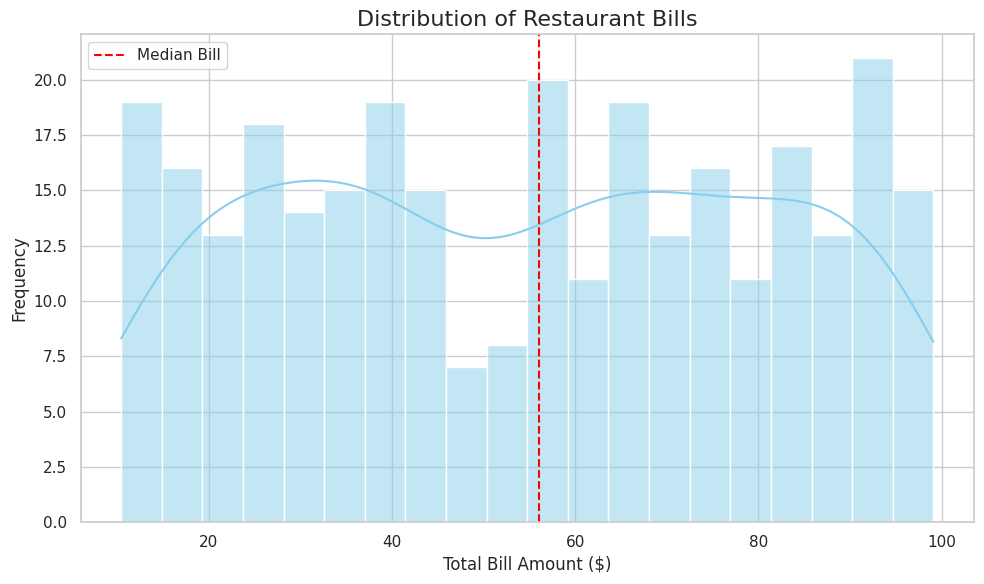

In [3]:
# Visualization 1: Distribution of Restaurant Bills

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="total_bill",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.axvline(
    df["total_bill"].median(),
    color="red",
    linestyle="--",
    label="Median Bill"
)

plt.title("Distribution of Restaurant Bills",
          fontsize=16)

plt.xlabel("Total Bill Amount ($)")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

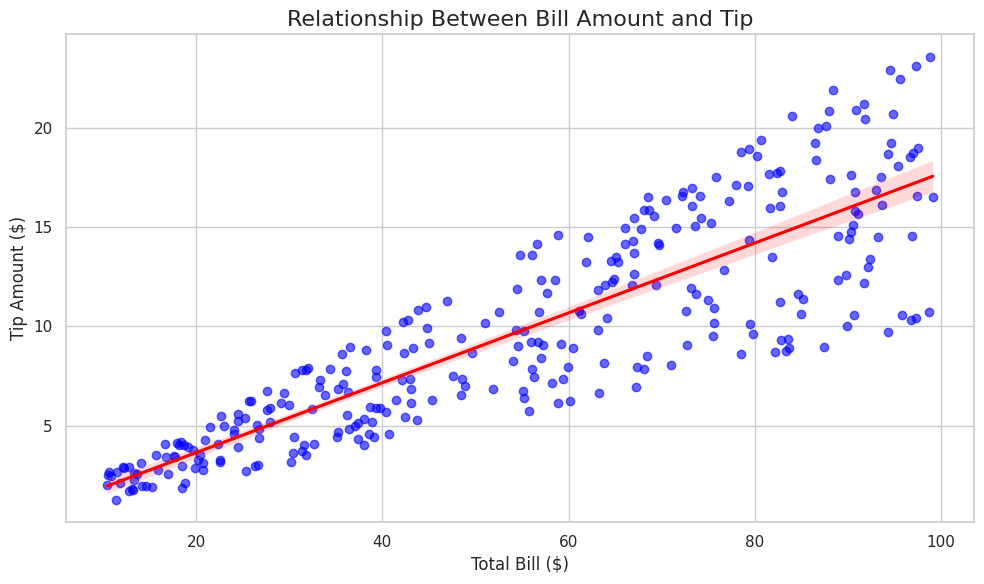

Pearson Correlation: 0.865


In [4]:
# Visualization 2: Bill Amount vs Tip Amount

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="total_bill",
    y="tip",
    scatter_kws={"alpha": 0.6, "color": "blue"},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Bill Amount and Tip",
          fontsize=16)

plt.xlabel("Total Bill ($)")
plt.ylabel("Tip Amount ($)")

plt.tight_layout()
plt.show()

# Calculate correlation
correlation = df["total_bill"].corr(df["tip"])

print("Pearson Correlation:", round(correlation, 3))

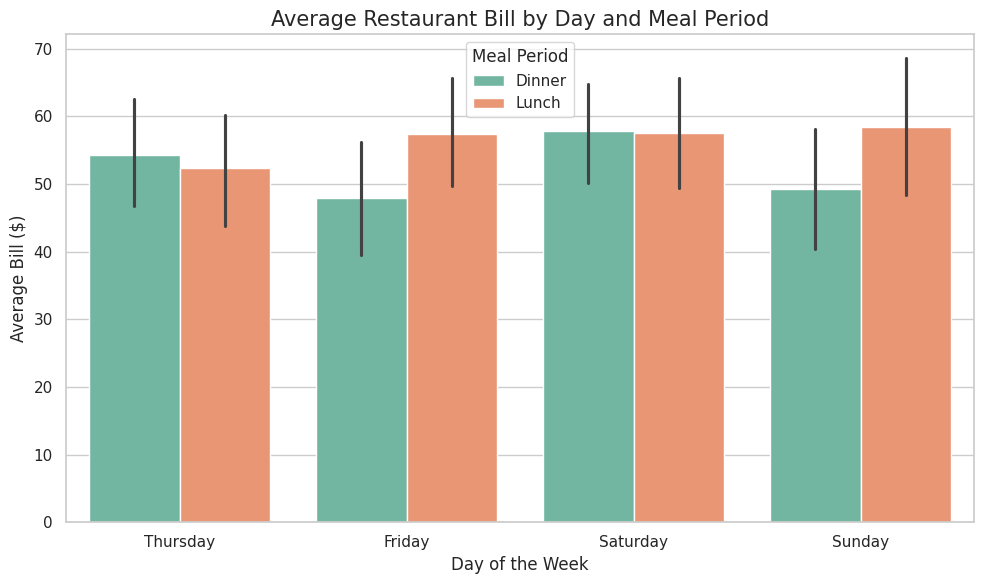

count   mean
day      time                
Friday   Dinner     37  47.96
         Lunch      44  57.41
Saturday Dinner     44  57.81
         Lunch      33  57.55
Sunday   Dinner     26  49.29
         Lunch      30  58.46
Thursday Dinner     43  54.37
         Lunch      43  52.40

In [5]:
# Visualization 3: Average Bill by Day and Meal Period

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="day",
    y="total_bill",
    hue="time",
    order=["Thursday", "Friday", "Saturday", "Sunday"],
    errorbar=("ci", 95),
    palette="Set2"
)

plt.title("Average Restaurant Bill by Day and Meal Period",
          fontsize=15)

plt.xlabel("Day of the Week")
plt.ylabel("Average Bill ($)")

plt.legend(title="Meal Period")
plt.tight_layout()
plt.show()

# Numerical comparison
display(
    df.groupby(["day", "time"])["total_bill"]
    .agg(["count", "mean"])
    .round(2)
)

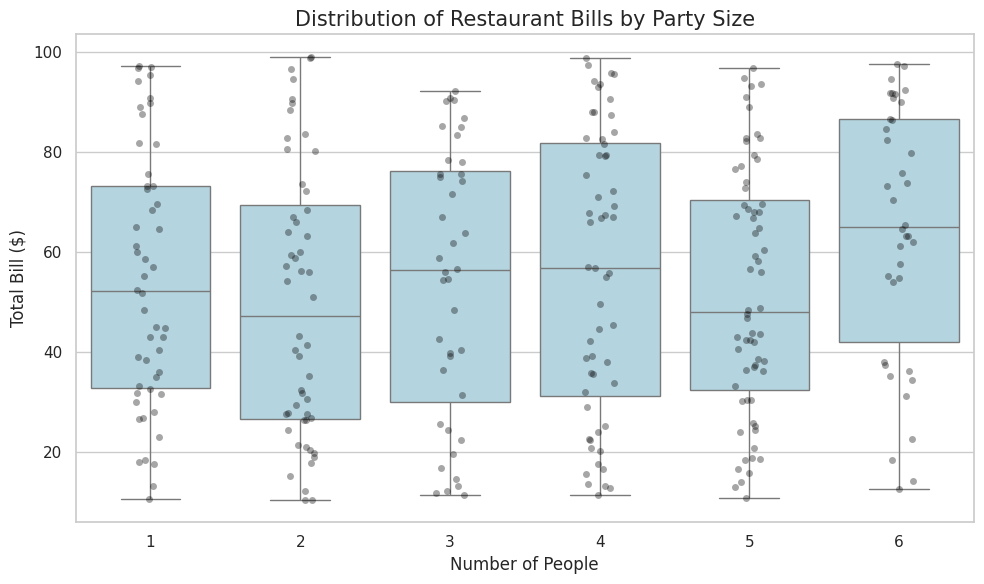

,count,mean,median,min,max
size,,,,,
1,50,54.32,52.20,10.63,97.29
2,52,49.86,47.18,10.46,99.10
3,40,53.92,56.36,11.49,92.19
4,56,56.08,56.90,11.39,98.71
5,64,52.06,48.05,10.83,96.91
6,38,64.03,64.96,12.75,97.57


In [6]:
# Visualization 4: Party Size vs Total Bill

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="size",
    y="total_bill",
    color="lightblue"
)

sns.stripplot(
    data=df,
    x="size",
    y="total_bill",
    color="black",
    alpha=0.35,
    jitter=True
)

plt.title("Distribution of Restaurant Bills by Party Size",
          fontsize=15)

plt.xlabel("Number of People")
plt.ylabel("Total Bill ($)")

plt.tight_layout()
plt.show()

# Numerical analysis
display(
    df.groupby("size")["total_bill"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

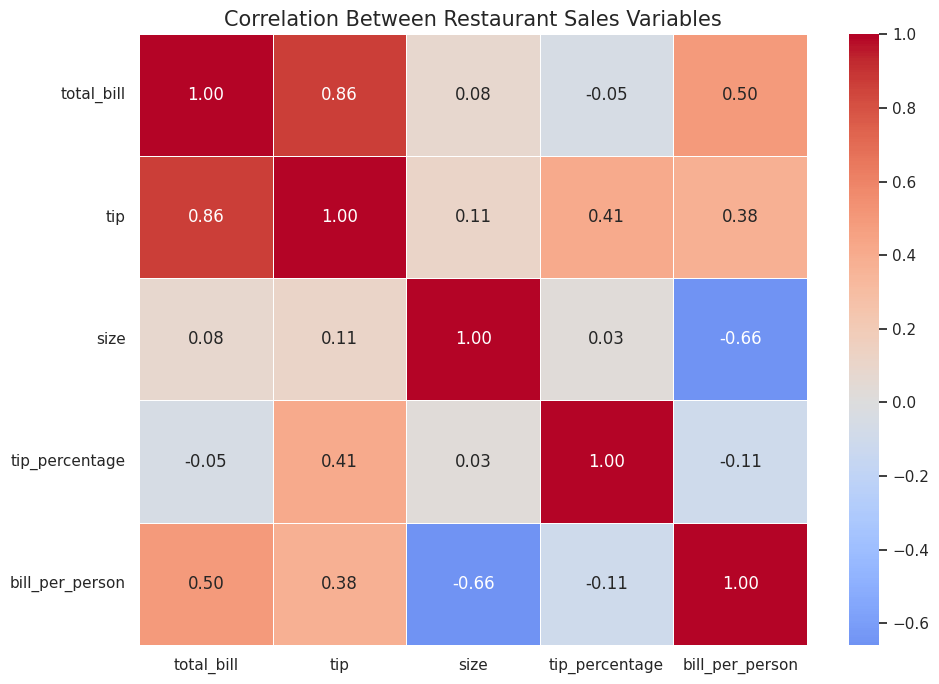

,total_bill,tip,size,tip_percentage,bill_per_person
total_bill,1.00,0.86,0.08,-0.05,0.50
tip,0.86,1.00,0.11,0.41,0.38
size,0.08,0.11,1.00,0.03,-0.66
tip_percentage,-0.05,0.41,0.03,1.00,-0.11
bill_per_person,0.50,0.38,-0.66,-0.11,1.00


In [7]:
# Visualization 5: Correlation Heatmap

numeric_columns = [
    "total_bill",
    "tip",
    "size",
    "tip_percentage",
    "bill_per_person"
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Restaurant Sales Variables",
          fontsize=15)

plt.tight_layout()
plt.show()

# Display correlation values
display(correlation_matrix.round(2))

In [8]:
# Visualization 6: Tip Percentage Across Different Days

import plotly.express as px

fig = px.box(
    df,
    x="day",
    y="tip_percentage",
    color="day",
    points="all",
    category_orders={
        "day": ["Thursday", "Friday", "Saturday", "Sunday"]
    },
    title="Distribution of Tip Percentage Across Different Days"
)

fig.update_layout(
    xaxis_title="Day of the Week",
    yaxis_title="Tip Percentage (%)",
    showlegend=False,
    template="plotly_white"
)

fig.show()

# Numerical comparison
display(
    df.groupby("day")["tip_percentage"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

,count,mean,median,min,max
day,,,,,
Friday,81,18.35,19.25,10.09,24.96
Saturday,77,17.91,17.32,10.36,24.97
Sunday,56,17.84,18.60,10.47,24.24
Thursday,86,17.64,18.11,10.63,24.91


In [9]:
# Final Statistical and Business Summary

print("========== OVERALL RESTAURANT ANALYSIS ==========")

print(f"Total Transactions: {len(df)}")
print(f"Average Bill: ${df['total_bill'].mean():.2f}")
print(f"Median Bill: ${df['total_bill'].median():.2f}")
print(f"Average Tip: ${df['tip'].mean():.2f}")
print(f"Average Tip Percentage: {df['tip_percentage'].mean():.2f}%")
print(f"Average Party Size: {df['size'].mean():.2f}")

print("\n========== SALES BY DAY ==========")

display(
    df.groupby("day")
    .agg(
        transactions=("total_bill", "count"),
        average_bill=("total_bill", "mean"),
        total_sales=("total_bill", "sum"),
        average_tip=("tip", "mean")
    )
    .round(2)
    .sort_values("total_sales", ascending=False)
)

print("\n========== SALES BY MEAL PERIOD ==========")

display(
    df.groupby("time")
    .agg(
        transactions=("total_bill", "count"),
        average_bill=("total_bill", "mean"),
        total_sales=("total_bill", "sum"),
        average_tip=("tip", "mean")
    )
    .round(2)
)

print("\n========== NUMERICAL RELATIONSHIP ==========")

print(
    "Correlation between bill and tip:",
    round(df["total_bill"].corr(df["tip"]), 3)
)

========== OVERALL RESTAURANT ANALYSIS ==========
Total Transactions: 300
Average Bill: $54.57
Median Bill: $56.05
Average Tip: $9.73
Average Tip Percentage: 17.94%
Average Party Size: 3.49

========== SALES BY DAY ==========


,transactions,average_bill,total_sales,average_tip
day,,,,
Thursday,86,53.39,4591.36,9.35
Saturday,77,57.70,4442.99,10.20
Friday,81,53.10,4300.83,9.69
Sunday,56,54.20,3035.34,9.71



========== SALES BY MEAL PERIOD ==========


,transactions,average_bill,total_sales,average_tip
time,,,,
Dinner,150,52.92,7937.99,9.29
Lunch,150,56.22,8432.54,10.16



========== NUMERICAL RELATIONSHIP ==========
Correlation between bill and tip: 0.865
